In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

## Загрузка данных

In [2]:
train_df = pd.read_csv("../data/train.csv")
train_df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [3]:
train_df.shape

(25000, 2)

## Баланс классов

In [4]:
train_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

## HTML-теги

In [5]:
print(train_df["text"][12500])

Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more striking in contrast with the natives.<br /><br />But I'd have to say that The Third Man has a more well-crafted storyline. Zentropa is a bit disjointed in this respect. Perhaps this is intentional: it is presented as a dream/nightmare, and making it too coherent would spoil the effect. <br /><br />This movie is unrelentingly grim--"noir" in more than one sense; one never sees the sun shine. Grim, but intriguing, and frightening.


In [6]:
train_df["text"].str.contains("<br").sum()

np.int64(14665)

## Длина отзывов

In [7]:
train_df["n_words"] = train_df["text"].str.split().str.len()
train_df["n_words"].describe()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64

In [8]:
train_df.head()

,text,label,n_words
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,288
1,"""I Am Curious: Yellow"" is a risible and preten...",0,214
2,If only to avoid making this type of film in t...,0,93
3,This film was probably inspired by Godard's Ma...,0,118
4,"Oh, brother...after hearing about this ridicul...",0,311


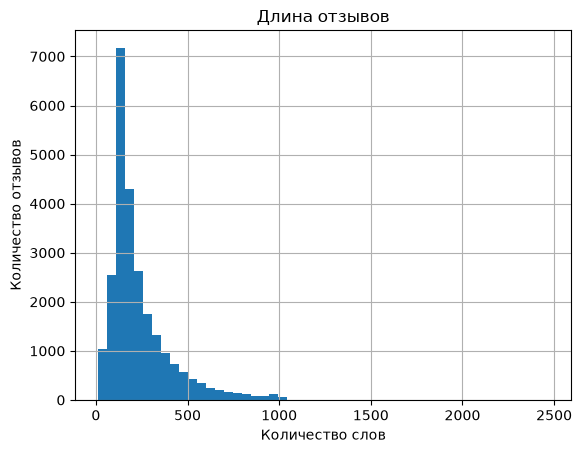

In [9]:
train_df["n_words"].hist(bins=50)
plt.xlabel("Количество слов")
plt.ylabel("Количество отзывов")
plt.title("Длина отзывов")
plt.show()

In [10]:
train_df.groupby("label")["n_words"].mean()

label
0    230.86784
1    236.70656
Name: n_words, dtype: float64

## Пропуски и дубликаты

In [11]:
print("Пустые значения:")
print(train_df.isna().sum())
print("Дубликаты:", train_df["text"].duplicated().sum())

Пустые значения:
text       0
label      0
n_words    0
dtype: int64
Дубликаты: 96


In [12]:
Markdown(f"""
## Выводы
1. **Размер:** {len(train_df)} отзывов.
2. **Баланс классов:** {train_df["label"].value_counts()[0]} отрицательных / {train_df["label"].value_counts()[1]} положительных.
3. **HTML-теги:** `<br>` есть в {train_df["text"].str.contains("<br").sum()} отзывах ({train_df["text"].str.contains("<br").sum() / len(train_df):.0%}).
4. **Длина:** медиана {train_df["n_words"].median():.0f} слов, по классам почти не различается.
5. **Дубликаты:** {train_df["text"].duplicated().sum()}, пропусков нет.

**Перед обучением:** удалить HTML-теги `<br />`, удалить дубликаты, перемешать строки.
""")


## Выводы
1. **Размер:** 25000 отзывов.
2. **Баланс классов:** 12500 отрицательных / 12500 положительных.
3. **HTML-теги:** `<br>` есть в 14665 отзывах (59%).
4. **Длина:** медиана 174 слов, по классам почти не различается.
5. **Дубликаты:** 96, пропусков нет.

**Перед обучением:** удалить HTML-теги `<br />`, удалить дубликаты, перемешать строки.


In [13]:
import sys
sys.path.append("..")
from ml.preprocess import clean_text

print(clean_text("Great film.<br /><br />Must see!"))

Great film. Must see!
